In [2]:
%pip install matplotlib

Note: you may need to restart the kernel to use updated packages.


# Can we tell if Sumeragi is cheating in Double Memory?

In [ ]:
## Step 1: Simulate Yumeko and Sumeragi's perfect play

In [3]:
import random

def play_game():
    deck = list(range(1, 53))
    unseen = [card for card in deck for _ in (0,1)]
    table = [card for card in deck for _ in (0,1)]
    seen = []
    scores = [0,0]
    turns = [0,0]
    player = 0

    streak = 0
    start_size = 0 
    all_streaks = []
    
    while table:   
        card_1 = random.choice(unseen)  
        unseen.remove(card_1)
        
        if card_1 not in seen:           
            seen.append(card_1)
            card_2 = random.choice(unseen)   
            unseen.remove(card_2)
            
            if card_1 == card_2:
                if streak == 0:
                    start_size = len(table)
                streak += 1
                    
                scores[player] += 1
                table.remove(card_1)
                table.remove(card_2)
            else:
                if streak > 0: 
                    all_streaks.append((start_size, streak)) 
                else:
                    all_streaks.append((len(table),0))
                streak = 0
                
                turns[player] += 1
                player = 1 - player
                if card_2 in seen:
                    start_size = len(table)
                    streak = 1
                    scores[player] += 1
                    table.remove(card_2)
                    table.remove(card_2)
            seen.append(card_2)
            
        else:
            if streak == 0:
                start_size = len(table)
            streak += 1
            scores[player] += 1
            seen.append(card_1)
            table.remove(card_1)
            table.remove(card_1)

    if streak > 0:
        all_streaks.append((start_size, streak))
    turns[player] += 1

    return scores, turns, all_streaks

result = play_game()
if result[0][0] == result[0][1]:
    print("Draw!")
else:
    winner = result[0].index(max(result[0]))
    szero = result[0][0]
    sone = result[0][1]
    tzero = result[1][0]
    tone = result[1][1]
    
    print("Winner is player", winner)
    print("Player 0 had", tzero,"turns, Player 1 had", tone, "turns.")
    print("Player 0 had", szero, "matched pairs, Player 1 had", sone, "matched pairs.")

Winner is player 1
Player 0 had 18 turns, Player 1 had 17 turns.
Player 0 had 24 matched pairs, Player 1 had 28 matched pairs.


In [20]:
## Step 2: Plot the distribution of turns and streaks over 10,000 games

Sumeragi's chance of getting 10 cards in a row--fraction reaching 5+: 0.6398601398601399
Yumeko's chance of winning--Percent of streaks starting at 18 that clear the board: 75.22511559990265
Yumeko was actually more likely than not to win despite Sumeragi's cheat! She drew the short stick for dramatization purposes
Sumeragi's play was indistinguishable from random chance.


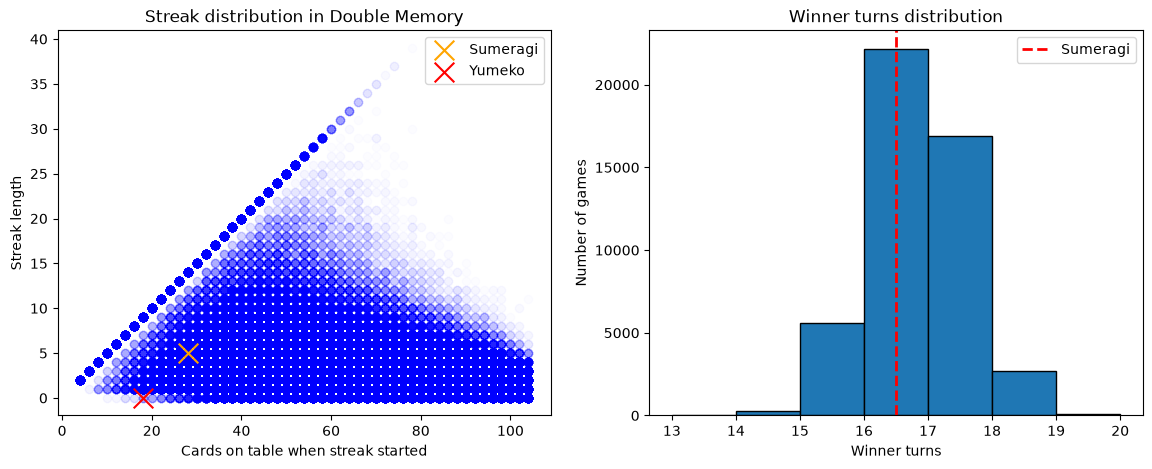

In [9]:
import matplotlib.pyplot as plt

starts = []
lengths = []
winner_turns = []

for _ in range(50000):
    scores, turns, all_streaks = play_game()
    if scores[0]>scores[1]:
        winner_turns.append(turns[0])
    elif scores[1] > scores[0]:
        winner_turns.append(turns[1])
        # ties skipped
    for start, length in all_streaks:   
        starts.append(start)
        lengths.append(length)

Sumeragi_turns = 16
Sumeragi_streak = [28, 5]

at_28 = [length for start, length in zip(starts, lengths) if start == 28]
long_ones = sum(1 for length in at_28 if length >=5)
print("Sumeragi's chance of getting 10 cards in a row--fraction reaching 5+:", long_ones / len(at_28))

at_18 = [length for start, length in zip(starts, lengths) if start == 18] 
sweeps = sum(1 for length in at_18 if length >= 9)
print("Yumeko's chance of winning--Percent of streaks starting at 18 that clear the board:", sweeps / len(at_18) * 100)
print("Yumeko was actually more likely than not to win despite Sumeragi's cheat! She drew the short stick for dramatization purposes")
print("Sumeragi's play was indistinguishable from random chance.")
fig, (ax1, ax2) = plt.subplots(1, 2, figsize = (14,5))

# Streaks
ax1.scatter(starts, lengths, alpha=0.01, color='blue')
ax1.scatter(Sumeragi_streak[0], Sumeragi_streak[1], color='orange', marker='x', s=200, label='Sumeragi')
ax1.scatter(18, 0, color='red', marker='x', s=200, label='Yumeko')
ax1.set_title('Streak distribution in Double Memory')
ax1.set_xlabel('Cards on table when streak started')
ax1.set_ylabel('Streak length')
ax1.legend()

# Turns
ax2.hist(winner_turns, bins=range(min(winner_turns), max(winner_turns)+2), edgecolor="black")
ax2.set_title('Winner turns distribution')
ax2.set_xlabel('Winner turns')
ax2.set_ylabel('Number of games')
ax2.axvline(Sumeragi_turns + 0.5, color='red', linestyle='--', linewidth=2, label='Sumeragi')
ax2.legend()

plt.savefig('charts.png', dpi=150)
plt.show()
